In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("../src")

import pandas as pd
from features import build_features

raw = pd.read_pickle("../data/raw/shots.pkl")
df = build_features(raw)
print(df.shape)

(5606, 27)


In [2]:
test_df = df[df["competition"] == "UEFA Euro 2024"]
train_df = df[df["competition"] != "UEFA Euro 2024"]

print(f"Train : {len(train_df)} tirs, taux de buts {train_df['is_goal'].mean():.1%}")
print(f"Test  : {len(test_df)} tirs, taux de buts {test_df['is_goal'].mean():.1%}")

Train : 4302 tirs, taux de buts 9.5%
Test  : 1304 tirs, taux de buts 7.5%


In [3]:
FEATURES = [
    "distance", "angle",
    "is_header", "under_pressure", "shot_first_time",
    "shot_one_on_one", "shot_open_goal",
    "n_def_in_cone", "n_def_close", "gk_dist_to_goal",
]

X_train = train_df[FEATURES]
y_train = train_df["is_goal"]
X_test = test_df[FEATURES]
y_test = test_df["is_goal"]

print(X_train.shape, X_test.shape)

(4302, 10) (1304, 10)


In [4]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logreg = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(max_iter=1000),
)
logreg.fit(X_train, y_train)

xg_logreg = logreg.predict_proba(X_test)[:, 1]
print(xg_logreg[:10])
print(f"\nxG total : {xg_logreg.sum():.1f}  |  buts réels : {y_test.sum()}")

[0.05261847 0.08769353 0.01660241 0.05637693 0.0255571  0.01257058
 0.29911199 0.02505897 0.07541226 0.06413335]

xG total : 109.7  |  buts réels : 98


In [5]:
import numpy as np
from sklearn.metrics import log_loss, brier_score_loss, roc_auc_score

xg_naive = np.full(len(y_test), y_train.mean())
xg_statsbomb = test_df["shot_statsbomb_xg"]

for name, preds in [("Naïf", xg_naive), ("Logreg", xg_logreg), ("StatsBomb", xg_statsbomb)]:
    print(f"{name:10} | log loss {log_loss(y_test, preds):.4f} "
          f"| Brier {brier_score_loss(y_test, preds):.4f} "
          f"| AUC {roc_auc_score(y_test, preds):.3f}")

Naïf       | log loss 0.2692 | Brier 0.0699 | AUC 0.500
Logreg     | log loss 0.2324 | Brier 0.0634 | AUC 0.767
StatsBomb  | log loss 0.2251 | Brier 0.0615 | AUC 0.787


In [6]:
coefs = pd.Series(
    logreg.named_steps["logisticregression"].coef_[0],
    index=FEATURES,
).sort_values()

coefs

distance          -0.618350
n_def_in_cone     -0.258190
is_header         -0.222277
n_def_close       -0.214740
under_pressure    -0.135906
shot_first_time    0.019482
shot_open_goal     0.053522
shot_one_on_one    0.100886
gk_dist_to_goal    0.259592
angle              0.495928
dtype: float64

In [7]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
)
xgb.fit(X_train, y_train)

xg_xgb = xgb.predict_proba(X_test)[:, 1]
print(f"xG total : {xg_xgb.sum():.1f}  |  buts réels : {y_test.sum()}")

xG total : 110.2  |  buts réels : 98


In [8]:
models = [("Naïf", xg_naive), ("Logreg", xg_logreg), ("XGBoost", xg_xgb), ("StatsBomb", xg_statsbomb)]

for name, preds in models:
    print(f"{name:10} | log loss {log_loss(y_test, preds):.4f} "
          f"| Brier {brier_score_loss(y_test, preds):.4f} "
          f"| AUC {roc_auc_score(y_test, preds):.3f}")

Naïf       | log loss 0.2692 | Brier 0.0699 | AUC 0.500
Logreg     | log loss 0.2324 | Brier 0.0634 | AUC 0.767
XGBoost    | log loss 0.2414 | Brier 0.0655 | AUC 0.738
StatsBomb  | log loss 0.2251 | Brier 0.0615 | AUC 0.787


In [9]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "max_depth": [2, 3, 4],
    "learning_rate": [0.03, 0.1],
    "n_estimators": [100, 300],
    "min_child_weight": [1, 10],
}

search = GridSearchCV(
    XGBClassifier(subsample=0.8, colsample_bytree=0.8, random_state=42),
    param_grid,
    scoring="neg_log_loss",
    cv=5,
)
search.fit(X_train, y_train)

print(search.best_params_)
print(f"Log loss en validation croisée : {-search.best_score_:.4f}")

{'learning_rate': 0.03, 'max_depth': 2, 'min_child_weight': 1, 'n_estimators': 300}
Log loss en validation croisée : 0.2612


In [10]:
xg_xgb_tuned = search.best_estimator_.predict_proba(X_test)[:, 1]

models = [("Naïf", xg_naive), ("Logreg", xg_logreg), ("XGBoost", xg_xgb),
          ("XGB réglé", xg_xgb_tuned), ("StatsBomb", xg_statsbomb)]

for name, preds in models:
    print(f"{name:10} | log loss {log_loss(y_test, preds):.4f} "
          f"| Brier {brier_score_loss(y_test, preds):.4f} "
          f"| AUC {roc_auc_score(y_test, preds):.3f}")

Naïf       | log loss 0.2692 | Brier 0.0699 | AUC 0.500
Logreg     | log loss 0.2324 | Brier 0.0634 | AUC 0.767
XGBoost    | log loss 0.2414 | Brier 0.0655 | AUC 0.738
XGB réglé  | log loss 0.2357 | Brier 0.0641 | AUC 0.754
StatsBomb  | log loss 0.2251 | Brier 0.0615 | AUC 0.787


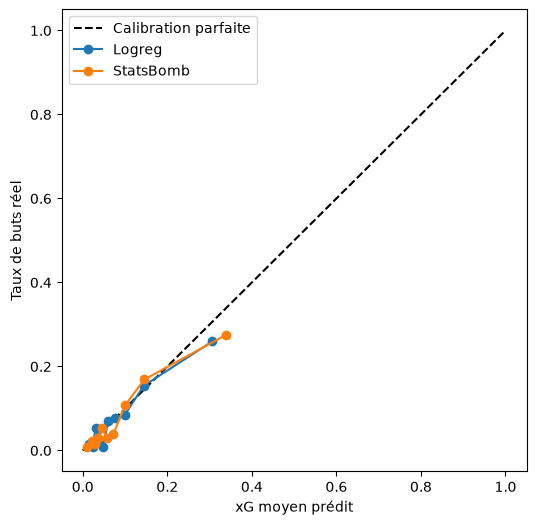

In [11]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], "k--", label="Calibration parfaite")

for name, preds in [("Logreg", xg_logreg), ("StatsBomb", xg_statsbomb)]:
    frac_goals, mean_xg = calibration_curve(y_test, preds, n_bins=10, strategy="quantile")
    ax.plot(mean_xg, frac_goals, "o-", label=name)

ax.set_xlabel("xG moyen prédit")
ax.set_ylabel("Taux de buts réel")
ax.legend()
plt.show()

In [12]:
import joblib
from features import FEATURES, add_distance_angle

model = joblib.load("../models/xg_model.joblib")

shot = pd.DataFrame([{
    "location": [108, 40],
    "is_header": 0, "under_pressure": 0, "shot_first_time": 0,
    "shot_one_on_one": 0, "shot_open_goal": 0,
    "n_def_in_cone": 0, "n_def_close": 0, "gk_dist_to_goal": 2,
}])
shot = add_distance_angle(shot)

xg = model.predict_proba(shot[FEATURES])[0, 1]
print(f"xG de ce tir : {xg:.2f}")

xG de ce tir : 0.20


In [13]:
def predict_xg(location, **kwargs):
    params = {
        "is_header": 0, "under_pressure": 0, "shot_first_time": 0,
        "shot_one_on_one": 0, "shot_open_goal": 0,
        "n_def_in_cone": 0, "n_def_close": 0, "gk_dist_to_goal": 2,
    }
    params.update(kwargs)
    shot = pd.DataFrame([{"location": location, **params}])
    shot = add_distance_angle(shot)
    return model.predict_proba(shot[FEATURES])[0, 1]


print(f"Pied, point de penalty : {predict_xg([108, 40]):.2f}")
print(f"Tête                   : {predict_xg([108, 40], is_header=1):.2f}")
print(f"3 défenseurs           : {predict_xg([108, 40], n_def_in_cone=3):.2f}")
print(f"De loin (25 yards)     : {predict_xg([95, 40]):.2f}")

Pied, point de penalty : 0.20
Tête                   : 0.12
3 défenseurs           : 0.10
De loin (25 yards)     : 0.05
